In [16]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore", message=".*inplace keyword.*")

t = yf.Ticker("FCNTX")
adj = t.history(start="2015-01-01", auto_adjust=True)["Close"]
raw = t.history(start="2015-01-01", auto_adjust=False)["Close"]

print(len(adj), adj.index.min().date(), adj.index.max().date())
adj.head()

2977 2015-01-02 2026-11-03


Date
2015-01-02 00:00:00-05:00    4.804191
2015-01-05 00:00:00-05:00    4.717243
2015-01-06 00:00:00-05:00    4.667629
2015-01-07 00:00:00-05:00    4.725594
2015-01-08 00:00:00-05:00    4.809593
Name: Close, dtype: float64

In [17]:
ret = adj.pct_change().dropna()
ret.describe()

count    2976.000000
mean        0.000650
std         0.012042
min        -0.118084
25%        -0.004422
50%         0.001035
75%         0.006746
max         0.097682
Name: Close, dtype: float64

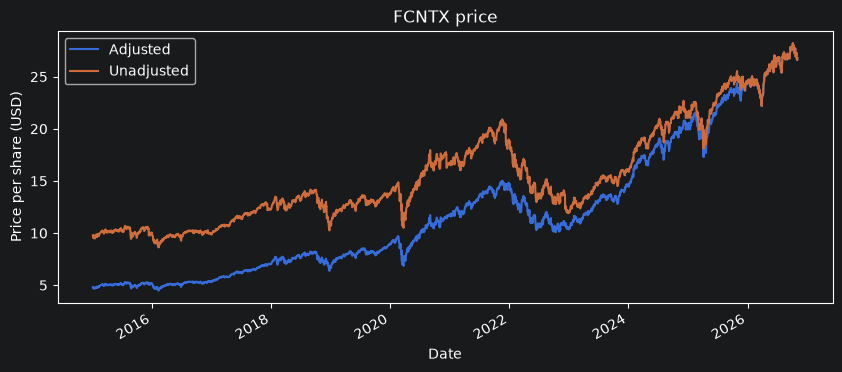

In [18]:
ax = adj.plot(label="Adjusted", figsize=(10, 4))
raw.plot(ax=ax, label="Unadjusted")
ax.legend()
ax.set_title("FCNTX price")
ax.set_xlabel("Date")
ax.set_ylabel("Price per share (USD)")
plt.show()

In [25]:
# Adjusted Price
first_adj = adj.iloc[0]
last_adj = adj.iloc[-1]
print(first_adj, last_adj)

# Raw Price
first_raw = raw.iloc[0]
last_raw = raw.iloc[-1]
print(first_raw, last_raw)

total_adj = (last_adj / first_adj) - 1
print(f"Adjusted total return: {total_adj:.1%}")

total_raw = (last_raw / first_raw) - 1
print(f"Raw total return: {total_raw:.1%}")

4.804190635681152 26.780000686645508
9.779999732971191 26.780000686645508
Adjusted total return: 457.4%
Raw total return: 173.8%
